# Машинное обучение в задачах распознавания тональности текста

In [ ]:
import pandas as pd
import numpy as np

## Сбор и предобработка данных

In [ ]:
data = pd.read_csv('data_emotions.csv')
data.head()

,text,label
0,i didnt feel humiliated,0
1,i can go from feeling so hopeless to so damned...,0
2,im grabbing a minute to post i feel greedy wrong,3
3,i am ever feeling nostalgic about the fireplac...,2
4,i am feeling grouchy,3


In [ ]:
data.shape

(18000, 2)

Датасет содержит 18000 строк и 2 столбца

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18000 entries, 0 to 17999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    18000 non-null  object
 1   label   18000 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 281.4+ KB


Все значения в датасете ненулевые

In [ ]:
print(f'''Минимальное число символов: {data['text'].str.len().min()}
Среднее число символов: {round(data['text'].str.len().mean())}
Максимальное число символов: {data['text'].str.len().max()}''')

Минимальное число символов: 7
Среднее число символов: 97
Максимальное число символов: 300


In [ ]:
labels_dict = {0:'sadness', 1:'joy', 2:'love', 3:'anger', 4:'fear', 5:'surprise'}
data['emotion'] = data['label'].map(labels_dict)
data.head()

,text,label,emotion
0,i didnt feel humiliated,0,sadness
1,i can go from feeling so hopeless to so damned...,0,sadness
2,im grabbing a minute to post i feel greedy wrong,3,anger
3,i am ever feeling nostalgic about the fireplac...,2,love
4,i am feeling grouchy,3,anger


In [ ]:
data[data[['text']].duplicated(keep = False) == True]

,text,label,emotion
112,i feel like some of you have pains and you can...,2,love
364,i tend to stop breathing when i m feeling stre...,0,sadness
1372,i loved the feeling i got during an amazing sl...,5,surprise
1501,i feel on the verge of tears from weariness i ...,2,love
1625,i was intensely conscious of how much cash i h...,3,anger
...,...,...,...
16917,i feel the need to pimp this since raini my be...,1,joy
16959,i feel cared for and accepted,2,love
17026,i have not conducted a survey but it is quite ...,0,sadness
17275,i feel so weird and scattered with all wonders...,5,surprise


Одинаковые предложения существуют, но нужно проверить, соответствуют ли им одинаковые эмоции.

Если нет - всё в порядке, предложения могут содержать в себе несколько эмоций.

Если такие дубликаты есть, их нужно убрать

In [ ]:
data[data[['emotion','text']].duplicated(keep = False) == True]

,text,label,emotion
4975,i feel more adventurous willing to take risks ...,1,joy
13846,i feel more adventurous willing to take risks ...,1,joy


In [ ]:
index_to_be_dropped = data[data[['emotion','text']].duplicated(keep = 'last') == True].index

In [ ]:
data.drop(index_to_be_dropped, inplace = True)

In [ ]:
data[['emotion','text']].duplicated(keep = False).sum()

0

Теперь полных дубликатов нет

In [ ]:
frequencies = [data[data['emotion'] == emotes].shape[0] for emotes in sorted(pd.unique(data['emotion']))]
emotions = sorted(pd.unique(data['emotion']))

freq_dict = dict(zip(emotions, frequencies))
freq_dict

{'anger': 2434,
 'fear': 2161,
 'joy': 6056,
 'love': 1463,
 'sadness': 5247,
 'surprise': 638}

<BarContainer object of 6 artists>

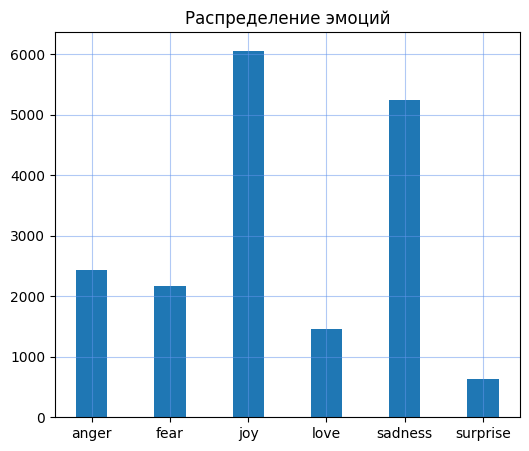

In [ ]:
from matplotlib import pyplot as plt
fig, ax = plt.subplots(figsize = (6,5))

ax.set_title('Распределение эмоций')
ax.grid(alpha = 0.5, color = 'cornflowerblue')
ax.bar(emotions, frequencies, width = 0.4)

### Токенизация

In [ ]:
for i in data['text']:
  if i.isupper():
    print(i)

Все слова в нижнем регистре

In [ ]:
import nltk
nltk.download('punkt')
from nltk.tokenize import word_tokenize

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.


In [ ]:
data['tokenized'] = data.apply(lambda row: nltk.word_tokenize(row['text']), axis=1)
tokenized = data['tokenized']
raw_text = data['text']

print(f'Изначальный текст: {raw_text[0]}\nПосле токенизации: {tokenized[0]}')

Изначальный текст: i didnt feel humiliated
После токенизации: ['i', 'didnt', 'feel', 'humiliated']


### Удаление стоп-слов

In [ ]:
from nltk.corpus import stopwords

In [ ]:
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

In [ ]:
stopwords_eng = stopwords.words('english')
print(stopwords_eng)

['i', 'me', 'my', 'myself', 'we', 'our', 'ours', 'ourselves', 'you', "you're", "you've", "you'll", "you'd", 'your', 'yours', 'yourself', 'yourselves', 'he', 'him', 'his', 'himself', 'she', "she's", 'her', 'hers', 'herself', 'it', "it's", 'its', 'itself', 'they', 'them', 'their', 'theirs', 'themselves', 'what', 'which', 'who', 'whom', 'this', 'that', "that'll", 'these', 'those', 'am', 'is', 'are', 'was', 'were', 'be', 'been', 'being', 'have', 'has', 'had', 'having', 'do', 'does', 'did', 'doing', 'a', 'an', 'the', 'and', 'but', 'if', 'or', 'because', 'as', 'until', 'while', 'of', 'at', 'by', 'for', 'with', 'about', 'against', 'between', 'into', 'through', 'during', 'before', 'after', 'above', 'below', 'to', 'from', 'up', 'down', 'in', 'out', 'on', 'off', 'over', 'under', 'again', 'further', 'then', 'once', 'here', 'there', 'when', 'where', 'why', 'how', 'all', 'any', 'both', 'each', 'few', 'more', 'most', 'other', 'some', 'such', 'no', 'nor', 'not', 'only', 'own', 'same', 'so', 'than', '

In [ ]:
data['no stopwords'] = tokenized.apply(lambda x: [word for word in x if word not in (stopwords_eng)])
no_stopwords = data['no stopwords']

print(f'После токенизации: {tokenized[0]}\nПосле удаления стоп-слов: {no_stopwords[0]}')

После токенизации: ['i', 'didnt', 'feel', 'humiliated']
После удаления стоп-слов: ['didnt', 'feel', 'humiliated']


### Лемматизация

In [ ]:
from nltk.stem import WordNetLemmatizer
nltk.download('wordnet')

[nltk_data] Downloading package wordnet to /root/nltk_data...


True

In [ ]:
lemmatizer = WordNetLemmatizer()

In [ ]:
data['lemmatized'] = no_stopwords.apply(lambda x: [lemmatizer.lemmatize(word) for word in x])
lemmatized = data['lemmatized']

print(f'После удаления стоп-слов: {no_stopwords[16634]}\nПосле лемматизации: {lemmatized[16634]}')

После удаления стоп-слов: ['feels', 'lame']
После лемматизации: ['feel', 'lame']


In [ ]:
data['lemmatized_str'] = lemmatized.apply(lambda x: " ".join([word for word in x]))
data

,text,label,emotion,tokenized,no stopwords,lemmatized,lemmatized_str
0,i didnt feel humiliated,0,sadness,"[i, didnt, feel, humiliated]","[didnt, feel, humiliated]","[didnt, feel, humiliated]",didnt feel humiliated
1,i can go from feeling so hopeless to so damned...,0,sadness,"[i, can, go, from, feeling, so, hopeless, to, ...","[go, feeling, hopeless, damned, hopeful, aroun...","[go, feeling, hopeless, damned, hopeful, aroun...",go feeling hopeless damned hopeful around some...
2,im grabbing a minute to post i feel greedy wrong,3,anger,"[im, grabbing, a, minute, to, post, i, feel, g...","[im, grabbing, minute, post, feel, greedy, wrong]","[im, grabbing, minute, post, feel, greedy, wrong]",im grabbing minute post feel greedy wrong
3,i am ever feeling nostalgic about the fireplac...,2,love,"[i, am, ever, feeling, nostalgic, about, the, ...","[ever, feeling, nostalgic, fireplace, know, st...","[ever, feeling, nostalgic, fireplace, know, st...",ever feeling nostalgic fireplace know still pr...
4,i am feeling grouchy,3,anger,"[i, am, feeling, grouchy]","[feeling, grouchy]","[feeling, grouchy]",feeling grouchy
...,...,...,...,...,...,...,...
17995,i just keep feeling like someone is being unki...,3,anger,"[i, just, keep, feeling, like, someone, is, be...","[keep, feeling, like, someone, unkind, wrong, ...","[keep, feeling, like, someone, unkind, wrong, ...",keep feeling like someone unkind wrong think g...
17996,im feeling a little cranky negative after this...,3,anger,"[im, feeling, a, little, cranky, negative, aft...","[im, feeling, little, cranky, negative, doctor...","[im, feeling, little, cranky, negative, doctor...",im feeling little cranky negative doctor appoi...
17997,i feel that i am useful to my people and that ...,1,joy,"[i, feel, that, i, am, useful, to, my, people,...","[feel, useful, people, gives, great, feeling, ...","[feel, useful, people, give, great, feeling, a...",feel useful people give great feeling achievement
17998,im feeling more comfortable with derby i feel ...,1,joy,"[im, feeling, more, comfortable, with, derby, ...","[im, feeling, comfortable, derby, feel, though...","[im, feeling, comfortable, derby, feel, though...",im feeling comfortable derby feel though start...


### Разделение выборки

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
data_x = data['lemmatized_str']
data_y = data['label']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    data_x, data_y,
    test_size=0.2,
    random_state = 42)

### Векторизация

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [ ]:
vectorizer = TfidfVectorizer()
X_train_vectorized = vectorizer.fit_transform(X_train).toarray()
X_test_vectorized = vectorizer.transform(X_test).toarray()

In [ ]:
X_train_vectorized

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]])

## Обучение моделей

In [ ]:
from sklearn.pipeline import Pipeline
import time

### Логистическая регрессия

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

In [ ]:
%%time

model = Pipeline([('tfidf', TfidfVectorizer()), ('lr', LogisticRegression(max_iter = 10000))])

start_time = time.time()
model.fit(X_train, y_train)
end_time = time.time()

time_fit = round(end_time - start_time, 2)

y_pred_tf = model.predict(X_test)
y_train_pred_tf = model.predict(X_train)

print(f'Training score: {round(accuracy_score(y_train, y_train_pred_tf), 6)*100}%')
print(f'Test score: {round(accuracy_score(y_test, y_pred_tf), 6)*100}%')
print(f'Время обучения: {time_fit} с\n')

Training score: 94.8677%
Test score: 86.13889999999999%
Время обучения: 4.96 с

CPU times: user 4.47 s, sys: 4.99 s, total: 9.47 s
Wall time: 5.23 s


Точность модели логистической регрессии:

 на обучающей выборка = 94.8677%

 на тестовой выборка = 86.1389%

 *accuracy score показывает отношение числа верных значений прогноза к общему числу*

### Метод опорных векторов

In [ ]:
from sklearn import svm

In [ ]:
%%time

model = Pipeline([('tfidf', TfidfVectorizer()), ('svm', svm.SVC())])

start_time = time.time()
model.fit(X_train, y_train)
end_time = time.time()

time_fit = round(end_time - start_time, 2)

y_pred_tf = model.predict(X_test)
y_train_pred_tf = model.predict(X_train)

print(f'Training score: {round(accuracy_score(y_train, y_train_pred_tf), 6)*100}%')
print(f'Test score: {round(accuracy_score(y_test, y_pred_tf), 6)*100}%')
print(f'Время обучения: {time_fit} с\n')

Training score: 99.1925%
Test score: 85.2%
Время обучения: 59.35 с

CPU times: user 1min 16s, sys: 1.19 s, total: 1min 18s
Wall time: 1min 27s


Точность метода опорных векторов:

 на обучающей выборка = 99.1925%

 на тестовой выборка = 85.2%

### Метод ближайших соседей

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

In [ ]:
%%time

model = Pipeline([('tfidf', TfidfVectorizer()), ('knc', KNeighborsClassifier(n_neighbors = 10))])

start_time = time.time()
model.fit(X_train, y_train)
end_time = time.time()

time_fit = round(end_time - start_time, 2)

y_pred_tf = model.predict(X_test)
y_train_pred_tf = model.predict(X_train)

print(f'Training score: {round(accuracy_score(y_train, y_train_pred_tf), 6)*100}%')
print(f'Test score: {round(accuracy_score(y_test, y_pred_tf), 6)*100}%')
print(f'Время обучения: {time_fit} с\n')

Training score: 85.8656%
Test score: 79.7333%
Время обучения: 0.17 с

CPU times: user 1min 5s, sys: 137 ms, total: 1min 6s
Wall time: 39.7 s


Точность метода опорных векторов:

 на обучающей выборка = 85.8656%

 на тестовой выборка = 79.7333%

### Наивный байесовский классификатор

In [ ]:
from sklearn.naive_bayes import MultinomialNB

In [ ]:
%%time

model = Pipeline([('tfidf', TfidfVectorizer()), ('nb', MultinomialNB(alpha = 0.2))])

start_time = time.time()
model.fit(X_train, y_train)
end_time = time.time()

time_fit = round(end_time - start_time, 2)

y_pred_tf = model.predict(X_test)
y_train_pred_tf = model.predict(X_train)

print(f"Training score: {round(accuracy_score(y_train, y_train_pred_tf), 6)*100}%")
print(f"Test score: {round(accuracy_score(y_test, y_pred_tf), 6)*100}%")
print(f'Время обучения: {time_fit} с\n')

Training score: 91.4216%
Test score: 75.66669999999999%
Время обучения: 0.54 с

CPU times: user 450 ms, sys: 2.1 ms, total: 452 ms
Wall time: 737 ms


Точность модели:

 на обучающей выборка = 91.4216%

 на тестовой выборка = 75.6667%

### Дерево решений

In [ ]:
from sklearn import tree

In [ ]:
%%time

model = Pipeline([('tfidf', TfidfVectorizer()), ('tr', tree.DecisionTreeClassifier(max_depth = 45))])

start_time = time.time()
model.fit(X_train, y_train)
end_time = time.time()

time_fit = round(end_time - start_time, 2)

y_pred_tf = model.predict(X_test)
y_train_pred_tf = model.predict(X_train)

print(f"Training score: {round(accuracy_score(y_train, y_train_pred_tf), 6)*100}%")
print(f"Test score: {round(accuracy_score(y_test, y_pred_tf), 6)*100}%")
print(f'Время обучения: {time_fit} с\n')

Training score: 51.6409%
Test score: 46.400000000000006%
Время обучения: 1.0 с

CPU times: user 1.21 s, sys: 4.15 ms, total: 1.21 s
Wall time: 1.21 s


Точность модели:

 на обучающей выборка = 51.6409%

 на тестовой выборка = 46.4%

## Подбор гиперпараметров

In [ ]:
from sklearn.model_selection import GridSearchCV

In [ ]:
model = Pipeline([
    ('tfidf', TfidfVectorizer()),
    ('lr', LogisticRegression(max_iter=10000))
])

param_grid = {
    'tfidf__max_df': [0.9, 1.0],
    'tfidf__min_df': [1, 5],
    'lr__C': [0.1, 1, 10],
}


grid_search = GridSearchCV(model, param_grid, cv=5, n_jobs=-1, verbose=2)

grid_search.fit(X_train, y_train)

print(f"Лучшие параметры: {grid_search.best_params_}")
print(f"Лучший score: {grid_search.best_score_}")

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Лучшие параметры: {'lr__C': 10, 'tfidf__max_df': 0.9, 'tfidf__min_df': 1}
Лучший score: 0.8811034888657326


In [ ]:
%%time

model = Pipeline([
    ('tfidf', TfidfVectorizer(max_df = 0.9, min_df = 1)),
     ('lr', LogisticRegression(max_iter = 10000, C = 10))])

start_time = time.time()
model.fit(X_train, y_train)
end_time = time.time()

time_fit = round(end_time - start_time, 2)

y_pred_tf = model.predict(X_test)
y_train_pred_tf = model.predict(X_train)

print(f'Training score: {round(accuracy_score(y_train, y_train_pred_tf), 6)*100}%')
print(f'Test score: {round(accuracy_score(y_test, y_pred_tf), 6)*100}%')
print(f'Время обучения: {time_fit} с\n')

Training score: 99.2569%
Test score: 87.8056%
Время обучения: 15.37 с

CPU times: user 9.45 s, sys: 10.2 s, total: 19.7 s
Wall time: 15.6 s


С помощью GridSearchCV удалось повысить точность модели с 86.1388% до 87.8056%

## Вывод

В ходе работы данные был проанализированы, очищены и приведены к форме, наиболее удобной для обучения.

Логистическая регрессия показала себя лучшей моделью классификации с точностью на тестовой выборке в 87.8056%